<a href="https://colab.research.google.com/github/ShachiPradhan/-cognevance_Student-Performance-Analysis/blob/main/Student_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving student_data.csv to student_data.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, f_oneway

# If using Colab:
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("student_data.csv")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()

# Remove duplicates if any
df = df.drop_duplicates()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
# Pass/Fail: in this dataset G3 is 0–20; pass usually >= 10
df['pass'] = np.where(df['G3'] >= 10, 'Pass', 'Fail')

# Attendance proxy: fewer absences = better attendance
df['attendance_band'] = pd.cut(
    df['absences'],
    bins=[-1, 5, 15, np.inf],
    labels=['High attendance (0-5 abs)', 'Medium (6-15 abs)', 'Low (>15 abs)']
)

# Grade change
df['grade_change_G1_G3'] = df['G3'] - df['G1']
df['grade_change_G2_G3'] = df['G3'] - df['G2']

# Encode binary categorical columns for correlation
binary_cols = [
    'school', 'sex', 'address', 'famsize', 'Pstatus',
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

for col in binary_cols:
    df[col + '_num'] = df[col].astype('category').cat.codes

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famsize_num,Pstatus_num,schoolsup_num,famsup_num,paid_num,activities_num,nursery_num,higher_num,internet_num,romantic_num
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,0,0,1,0,0,0,1,1,0,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,0,1,0,1,0,0,0,1,1,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,1,1,1,0,1,0,1,1,1,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,0,1,0,1,1,1,1,1,1,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,0,1,0,1,1,0,1,1,0,0


In [ ]:
df.to_csv("student_data_cleaned.csv", index=False)


In [ ]:
print(df[['G1', 'G2', 'G3', 'absences']].describe())

               G1          G2          G3    absences
count  395.000000  395.000000  395.000000  395.000000
mean    10.908861   10.713924   10.415190    5.708861
std      3.319195    3.761505    4.581443    8.003096
min      3.000000    0.000000    0.000000    0.000000
25%      8.000000    9.000000    8.000000    0.000000
50%     11.000000   11.000000   11.000000    4.000000
75%     13.000000   13.000000   14.000000    8.000000
max     19.000000   19.000000   20.000000   75.000000


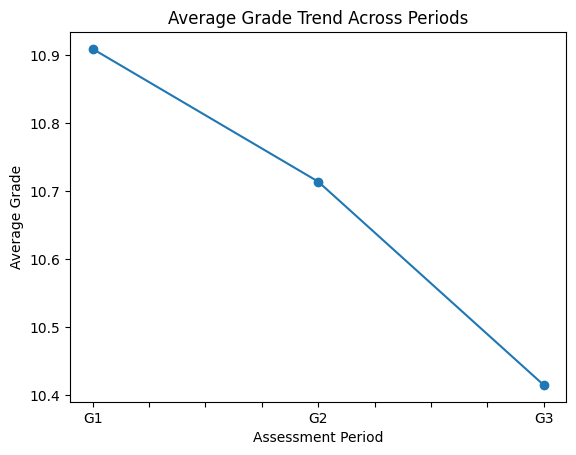

In [ ]:
df[['G1', 'G2', 'G3']].mean().plot(kind='line', marker='o')
plt.title('Average Grade Trend Across Periods')
plt.ylabel('Average Grade')
plt.xlabel('Assessment Period')
plt.show()

In [ ]:
pass_rate = df['pass'].value_counts(normalize=True) * 100
print(pass_rate)

pass
Pass    67.088608
Fail    32.911392
Name: proportion, dtype: float64


In [ ]:
# Average final grade by sex
print(df.groupby('sex')['G3'].mean())

# By school
print(df.groupby('school')['G3'].mean())

# By study time
print(df.groupby('studytime')['G3'].mean())

# By failures
print(df.groupby('failures')['G3'].mean())

# By attendance band
print(df.groupby('attendance_band')['G3'].agg(['mean', 'count']))

sex
F     9.966346
M    10.914439
Name: G3, dtype: float64
school
GP    10.489971
MS     9.847826
Name: G3, dtype: float64
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64
failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64
                                mean  count
attendance_band                            
High attendance (0-5 abs)  10.168675    249
Medium (6-15 abs)          11.070796    113
Low (>15 abs)              10.030303     33


/tmp/ipykernel_2872/3495098781.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('attendance_band')['G3'].agg(['mean', 'count']))


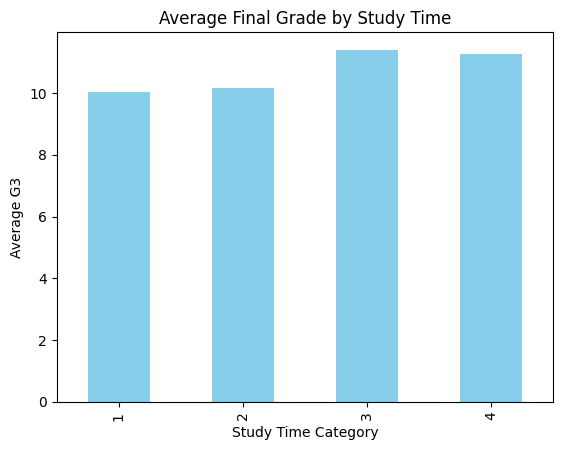

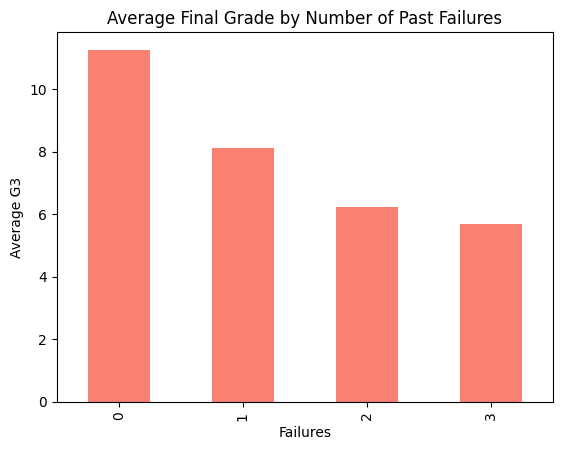

/tmp/ipykernel_2872/3323113543.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('attendance_band')['G3'].mean().plot(kind='bar', color='lightgreen')


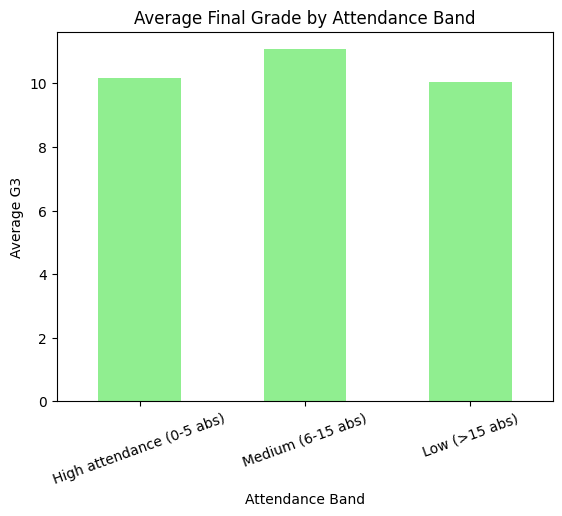

In [ ]:
# Average final grade by study time
df.groupby('studytime')['G3'].mean().plot(kind='bar', color='skyblue')
plt.title('Average Final Grade by Study Time')
plt.xlabel('Study Time Category')
plt.ylabel('Average G3')
plt.show()

# Average final grade by failures
df.groupby('failures')['G3'].mean().plot(kind='bar', color='salmon')
plt.title('Average Final Grade by Number of Past Failures')
plt.xlabel('Failures')
plt.ylabel('Average G3')
plt.show()

# Average final grade by attendance band
df.groupby('attendance_band')['G3'].mean().plot(kind='bar', color='lightgreen')
plt.title('Average Final Grade by Attendance Band')
plt.xlabel('Attendance Band')
plt.ylabel('Average G3')
plt.xticks(rotation=20)
plt.show()

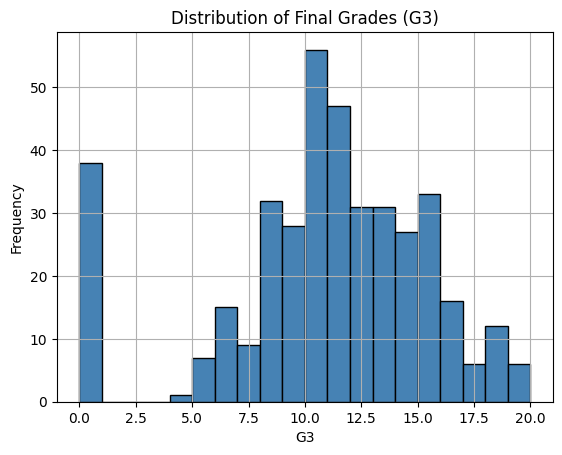

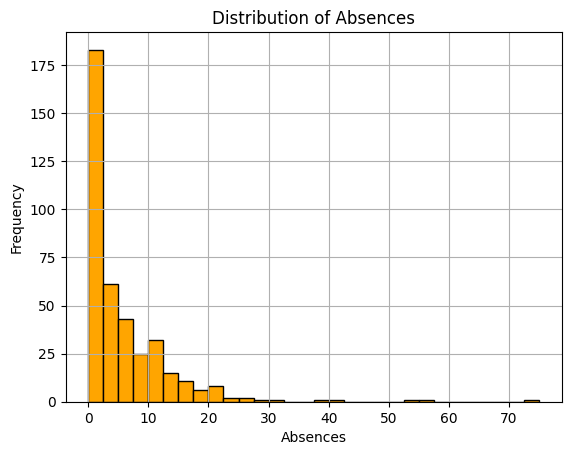

In [ ]:
df['G3'].hist(bins=20, color='steelblue', edgecolor='black')
plt.title('Distribution of Final Grades (G3)')
plt.xlabel('G3')
plt.ylabel('Frequency')
plt.show()

df['absences'].hist(bins=30, color='orange', edgecolor='black')
plt.title('Distribution of Absences')
plt.xlabel('Absences')
plt.ylabel('Frequency')
plt.show()

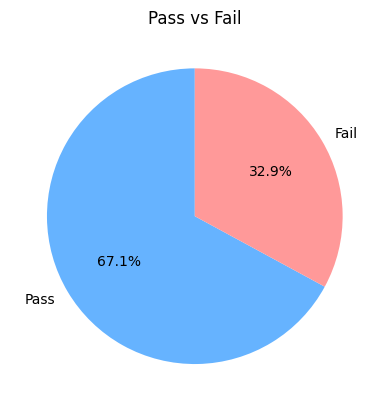

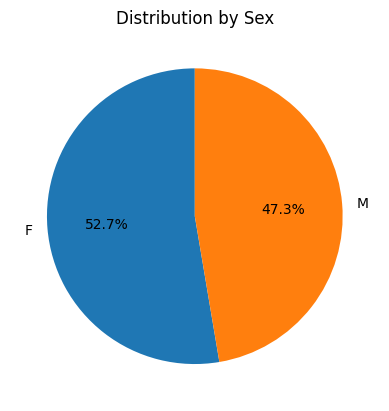

In [ ]:
df['pass'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff9999']
)
plt.title('Pass vs Fail')
plt.ylabel('')
plt.show()

df['sex'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', startangle=90
)
plt.title('Distribution by Sex')
plt.ylabel('')
plt.show()

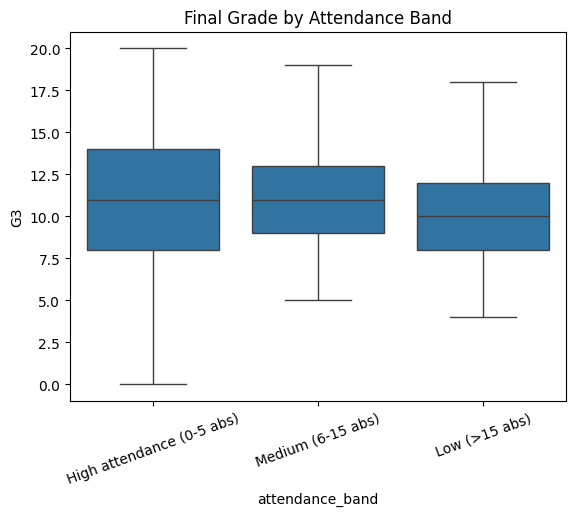

In [ ]:
sns.boxplot(data=df, x='attendance_band', y='G3')
plt.title('Final Grade by Attendance Band')
plt.xticks(rotation=20)
plt.show()

In [ ]:
print(df[['absences', 'G1', 'G2', 'G3']].corr())

r, p = pearsonr(df['absences'], df['G3'])
print(f"Correlation between absences and G3: r = {r:.3f}, p-value = {p:.3f}")

          absences        G1        G2        G3
absences  1.000000 -0.031003 -0.031777  0.034247
G1       -0.031003  1.000000  0.852118  0.801468
G2       -0.031777  0.852118  1.000000  0.904868
G3        0.034247  0.801468  0.904868  1.000000
Correlation between absences and G3: r = 0.034, p-value = 0.497


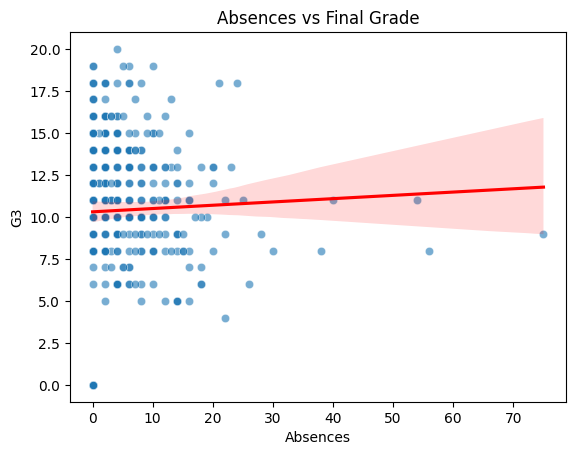

In [ ]:
sns.scatterplot(data=df, x='absences', y='G3', alpha=0.6)
sns.regplot(data=df, x='absences', y='G3', scatter=False, color='red')
plt.title('Absences vs Final Grade')
plt.xlabel('Absences')
plt.ylabel('G3')
plt.show()

In [ ]:
groups = [group['G3'].values for name, group in df.groupby('attendance_band')]
f_stat, p_val = f_oneway(*groups)
print(f"ANOVA F = {f_stat:.3f}, p = {p_val:.3f}")

ANOVA F = 1.639, p = 0.195


/tmp/ipykernel_2872/2915322579.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = [group['G3'].values for name, group in df.groupby('attendance_band')]


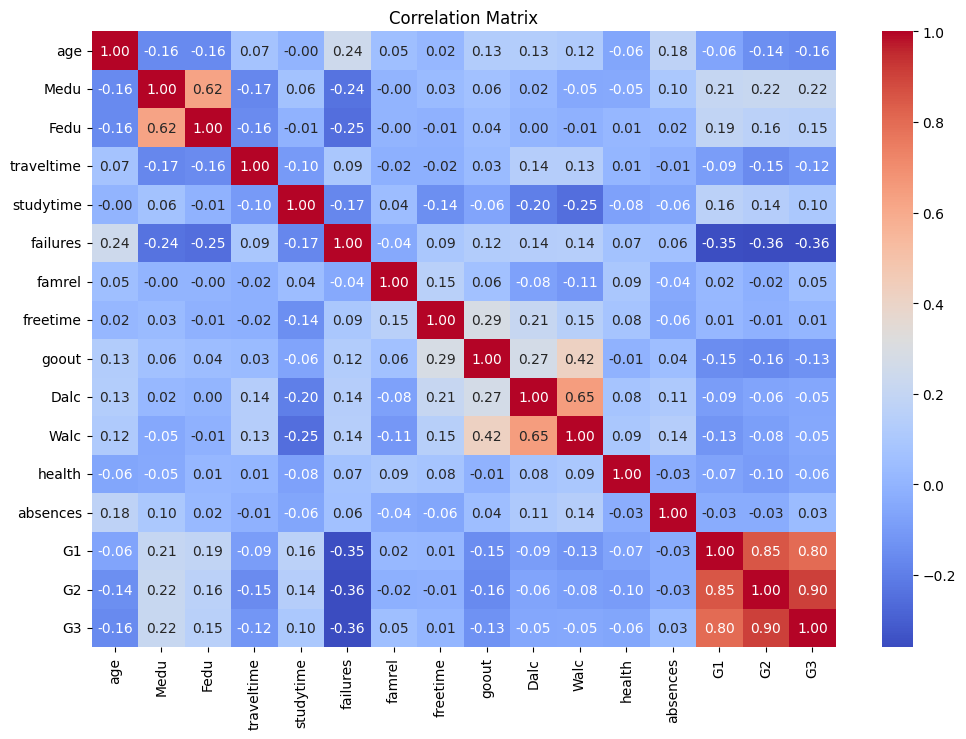

In [ ]:
corr_cols = [
    'age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures',
    'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health',
    'absences', 'G1', 'G2', 'G3'
]

plt.figure(figsize=(12, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()